# 02 · Exploratory Data Analysis
**Netflix Customer Intelligence, Churn Prediction & AI Analytics Copilot**

Input: cleaned CSVs from `01_data_cleaning.ipynb` (`data/processed/`). **30 charts** across the 7 areas the PRD requires, each saved to `reports/figures/`.

| Section | Charts |
|---|---|
| A. Customers & acquisition | 1 – 4 |
| B. Plans & revenue | 5 – 7 |
| C. Cancellations | 8 – 10 |
| D. Engagement | 11 – 17 |
| E. Churn drivers (churn rate by country, channel, tenure, engagement, payments, tickets, auto-renew) | 18 – 25 |
| F. Support & feedback | 26 – 31 |
| G. Correlation overview | 32 |

*Reading note:* every chart prints a one-line **Takeaway** computed from the data, so the text always matches the picture.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')

PROC = Path('../data/processed'); FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
REF = pd.Timestamp('2026-06-30')

sns.set_theme(style='whitegrid', context='notebook')
RED, GREY, BLUE, GREEN = '#E50914', '#8C8C8C', '#2B6CB0', '#2F855A'      # Netflix red as the "churn" colour
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.spines.top': False, 'axes.spines.right': False})

_n = [0]
def save(fig, name):
    _n[0] += 1
    fig.tight_layout(); fig.savefig(FIG / f'{_n[0]:02d}_{name}.png', dpi=130, bbox_inches='tight'); plt.show()
    return _n[0]
def take(text): print('Takeaway:', text)

def rd(n, **kw): return pd.read_csv(PROC / f'{n}.csv', **kw)
customers = rd('customers', parse_dates=['registration_date']); plans = rd('subscription_plans')
subs = rd('subscriptions', parse_dates=['subscription_start_date','subscription_end_date','cancellation_date'])
content = rd('content'); viewing = rd('viewing_activity', parse_dates=['viewing_date'])
payments = rd('payments', parse_dates=['payment_date']); tickets = rd('support_tickets', parse_dates=['ticket_date'])
feedback = rd('customer_feedback', parse_dates=['feedback_date']); churn = rd('churn_labels', parse_dates=['churn_date'])
print({k: len(v) for k, v in dict(customers=customers, subs=subs, viewing=viewing, payments=payments, tickets=tickets, feedback=feedback).items()})

{'customers': 8000, 'subs': 8875, 'viewing': 66422, 'payments': 110735, 'tickets': 6120, 'feedback': 5046}


## Build one customer-level analysis table
One row per customer with the churn label, current plan, tenure, 90-day engagement, payment and support history.
*Engagement is measured over the 90 days before the customer's observation end (churn date for churned customers, 2026-06-30 for active ones), so churned customers are not penalised for time after they left.*

In [2]:
cur = (subs.sort_values(['customer_id','subscription_start_date']).groupby('customer_id').tail(1)
       .merge(plans[['plan_id','plan_name']], on='plan_id')[['customer_id','plan_name','monthly_price','auto_renew']])
cust = customers.merge(churn, on='customer_id').merge(cur, on='customer_id')
cust['churned'] = cust.churned.astype(int)
cust['obs_end'] = cust.churn_date.fillna(REF)
cust['tenure_days'] = (cust.obs_end - cust.registration_date).dt.days
cust['tenure_bucket'] = pd.cut(cust.tenure_days, [-1,180,365,730,1095,1825,99999],
                               labels=['0-6 mo','6-12 mo','1-2 yr','2-3 yr','3-5 yr','5+ yr'])

# 90-day engagement before observation end
vv = viewing.merge(cust[['customer_id','obs_end']], on='customer_id')
win = vv[(vv.viewing_date > vv.obs_end - pd.Timedelta(days=90)) & (vv.viewing_date <= vv.obs_end)]
eng = win.groupby('customer_id').agg(sessions_90d=('viewing_id','count'), minutes_90d=('watch_duration_minutes','sum'))
cust = cust.merge(eng, on='customer_id', how='left').fillna({'sessions_90d': 0, 'minutes_90d': 0})
pos = cust.minutes_90d > 0
cust['engagement_tier'] = 'No activity'
cust.loc[pos, 'engagement_tier'] = pd.qcut(cust.loc[pos,'minutes_90d'].rank(method='first'), 4, labels=['Low','Medium','High','Very high']).astype(str)
cust['engagement_tier'] = pd.Categorical(cust.engagement_tier, ['No activity','Low','Medium','High','Very high'], ordered=True)

# payments
payments['is_failed'] = (payments.payment_status == 'Failed').astype(int)
ps = payments.groupby('customer_id').agg(payments=('payment_id','count'), failed_payments=('is_failed','sum'))
ps['failure_rate'] = ps.failed_payments / ps.payments
cust = cust.merge(ps, on='customer_id', how='left')
cust['failed_bucket'] = pd.cut(cust.failed_payments, [-1,0,1,2,999], labels=['0','1','2','3+'])

# support
ts = tickets.groupby('customer_id').agg(ticket_count=('ticket_id','count'), avg_csat=('customer_satisfaction_score','mean'))
cust = cust.merge(ts, on='customer_id', how='left'); cust['ticket_count'] = cust.ticket_count.fillna(0).astype(int)
cust['ticket_bucket'] = pd.cut(cust.ticket_count, [-1,0,1,2,3,999], labels=['0','1','2','3','4+'])
cust['age_group'] = pd.cut(cust.age, [12,24,34,44,54,100], labels=['13-24','25-34','35-44','45-54','55+'])
BASE = cust.churned.mean()
print(f'{len(cust):,} customers | overall churn {BASE:.2%}'); cust.head(3).T

8,000 customers | overall churn 24.89%


,0,1,2
customer_id,CUST000744,CUST001502,CUST005383
first_name,Riya,Ananya,Zara
last_name,Santos,Hussain,Banda
age,21,31,40
gender,Female,Male,Male
country,United Kingdom,Canada,United Kingdom
state_or_region,NaN,NaN,NaN
city,Liverpool,Montreal,Leeds
registration_date,2019-06-03 00:00:00,2026-01-13 00:00:00,2023-06-17 00:00:00
acquisition_channel,Organic Search,Referral,Paid Social


In [3]:
def churn_bar(col, title, name, order=None, rotate=0, horizontal=False, top=None, figsize=(8,4.6)):
    g = cust.groupby(col, observed=True).agg(customers=('churned','size'), churn_rate=('churned','mean')).reset_index()
    if order is not None: g = g.set_index(col).loc[order].reset_index()
    elif top: g = g.sort_values('churn_rate', ascending=False).head(top)
    fig, ax = plt.subplots(figsize=figsize)
    x = g[col].astype(str)
    if horizontal:
        bars = ax.barh(x, g.churn_rate*100, color=RED); ax.axvline(BASE*100, color='black', ls='--', lw=1)
        ax.invert_yaxis(); ax.set_xlabel('Churn rate (%)')
        for b, (r, n) in zip(bars, zip(g.churn_rate, g.customers)): ax.text(b.get_width()+.3, b.get_y()+b.get_height()/2, f'{r:.1%} (n={n:,})', va='center', fontsize=8)
    else:
        bars = ax.bar(x, g.churn_rate*100, color=RED); ax.axhline(BASE*100, color='black', ls='--', lw=1)
        ax.set_ylabel('Churn rate (%)'); plt.setp(ax.get_xticklabels(), rotation=rotate, ha='right' if rotate else 'center')
        for b, (r, n) in zip(bars, zip(g.churn_rate, g.customers)): ax.text(b.get_x()+b.get_width()/2, b.get_height()+.3, f'{r:.1%}\nn={n:,}', ha='center', fontsize=8)
    ax.set_title(title + f'  (dashed = overall {BASE:.1%})'); save(fig, name); return g

## A · Customers & acquisition

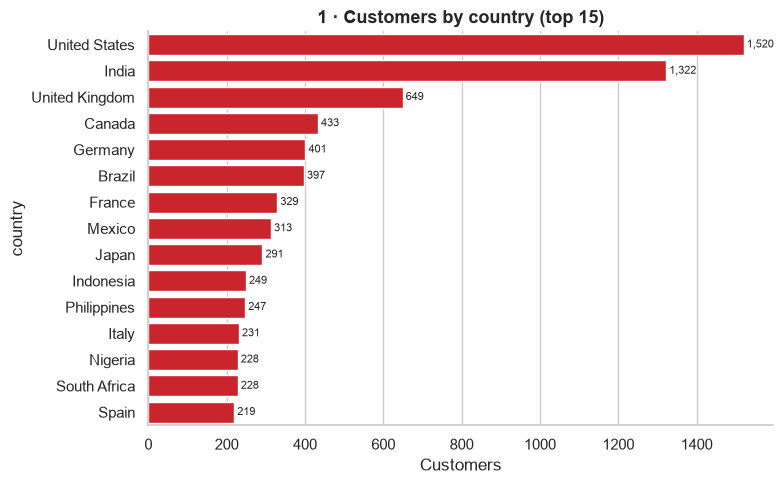

Takeaway: United States and India together hold 36% of all customers; 20 countries in total.


In [4]:
# 1 customers by country
s = cust.country.value_counts().head(15)
fig, ax = plt.subplots(figsize=(8,5)); sns.barplot(x=s.values, y=s.index, color=RED, ax=ax)
for i, v in enumerate(s.values): ax.text(v+8, i, f'{v:,}', va='center', fontsize=8)
ax.set_title('1 · Customers by country (top 15)'); ax.set_xlabel('Customers'); save(fig, 'customers_by_country')
take(f"{s.index[0]} and {s.index[1]} together hold {(s.iloc[0]+s.iloc[1])/len(cust):.0%} of all customers; {cust.country.nunique()} countries in total.")

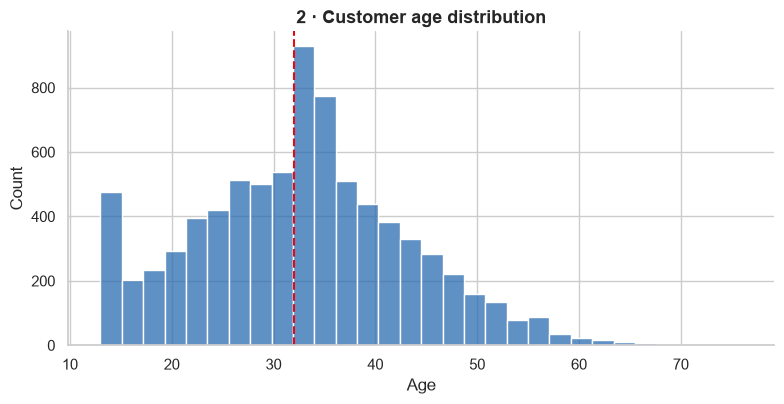

Takeaway: median age 32; 64% of customers are 25-44. (A spike at 13 reflects age clipping in the source data.)


In [5]:
# 2 age distribution
fig, ax = plt.subplots(figsize=(8,4.2)); sns.histplot(cust.age, bins=30, color=BLUE, ax=ax); ax.axvline(cust.age.median(), color=RED, ls='--')
ax.set_title('2 · Customer age distribution'); ax.set_xlabel('Age'); save(fig, 'age_distribution')
take(f"median age {cust.age.median():.0f}; {(cust.age.between(25,44)).mean():.0%} of customers are 25-44. (A spike at 13 reflects age clipping in the source data.)")

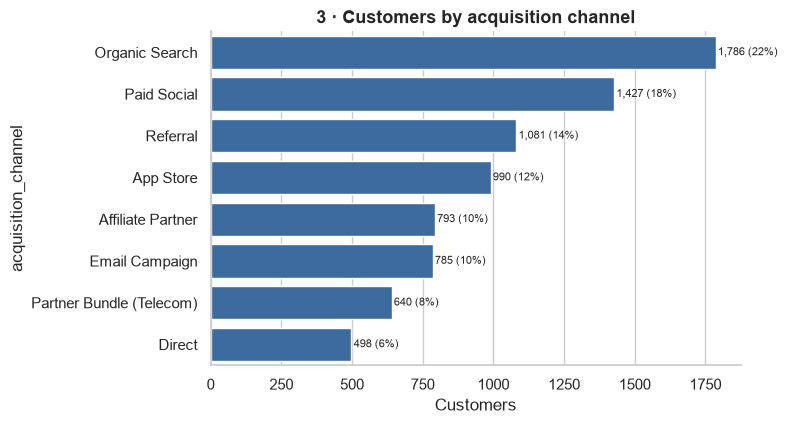

Takeaway: Organic Search is the largest channel (22%); the smallest is Direct (6%).


In [6]:
# 3 acquisition channel
s = cust.acquisition_channel.value_counts()
fig, ax = plt.subplots(figsize=(8,4.4)); sns.barplot(x=s.values, y=s.index, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(v+8, i, f'{v:,} ({v/len(cust):.0%})', va='center', fontsize=8)
ax.set_title('3 · Customers by acquisition channel'); ax.set_xlabel('Customers'); save(fig, 'acquisition_channel')
take(f"{s.index[0]} is the largest channel ({s.iloc[0]/len(cust):.0%}); the smallest is {s.index[-1]} ({s.iloc[-1]/len(cust):.0%}).")

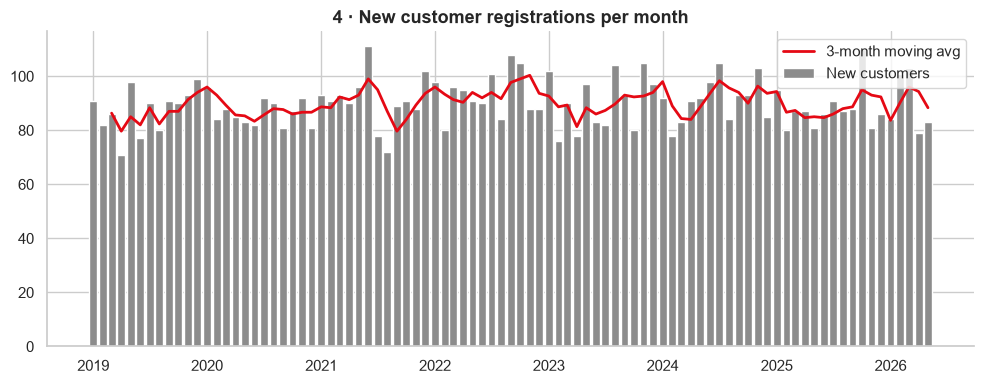

Takeaway: acquisition is flat at roughly 1079 customers/year (2019-2025); 2026 has 450 through May.


In [7]:
# 4 registrations per month + 3-month moving average
m = customers.set_index('registration_date').resample('MS').size()
fig, ax = plt.subplots(figsize=(10,4)); ax.bar(m.index, m.values, width=25, color=GREY, label='New customers')
ax.plot(m.index, m.rolling(3).mean(), color=RED, lw=2, label='3-month moving avg'); ax.legend()
ax.set_title('4 · New customer registrations per month'); save(fig, 'registrations_monthly')
yr = customers.registration_date.dt.year.value_counts().sort_index()
take(f"acquisition is flat at roughly {yr.loc[2019:2025].mean():.0f} customers/year (2019-2025); 2026 has {yr.loc[2026]} through May.")

## B · Plans & revenue

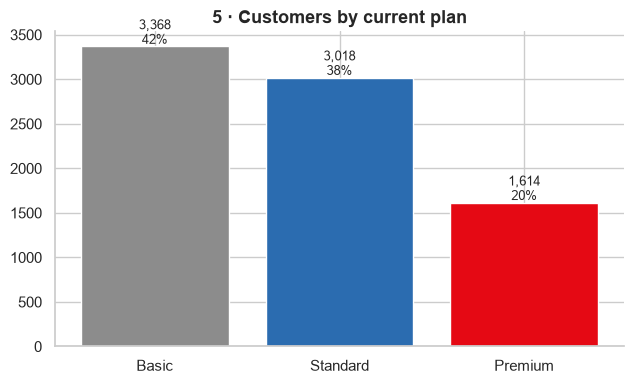

Takeaway: Basic is the most common plan (42%), Premium the least (20%).


In [8]:
# 5 plan distribution
order = ['Basic','Standard','Premium']
s = cust.plan_name.value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(6.5,4)); bars = ax.bar(s.index, s.values, color=[GREY, BLUE, RED])
for b, v in zip(bars, s.values): ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}\n{v/len(cust):.0%}', ha='center', fontsize=9)
ax.set_title('5 · Customers by current plan'); save(fig, 'plan_distribution')
take(f"Basic is the most common plan ({s['Basic']/len(cust):.0%}), Premium the least ({s['Premium']/len(cust):.0%}).")

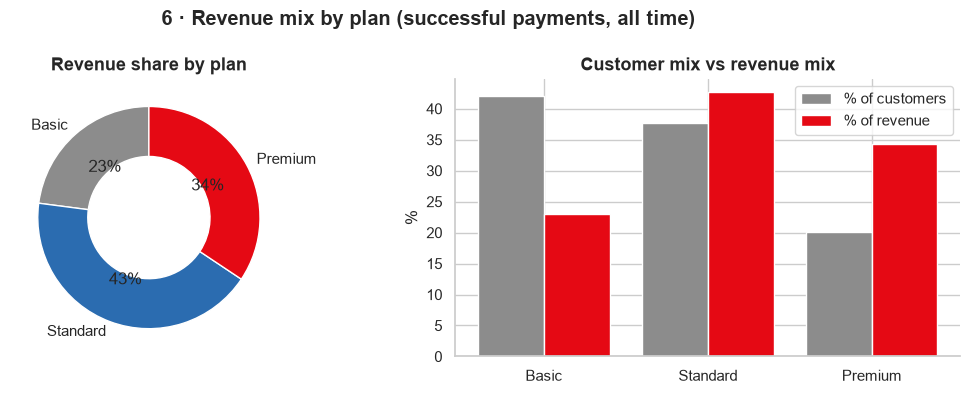

Takeaway: Standard earns the most ($594K, 43%); Basic is 42% of customers but only 23% of revenue.


In [9]:
# 6 revenue mix
pr = payments[payments.payment_status=='Success'].merge(subs[['subscription_id','plan_id']], on='subscription_id').merge(plans[['plan_id','plan_name']], on='plan_id')
rev = pr.groupby('plan_name').amount.sum().reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].pie(rev.values, labels=rev.index, autopct='%1.0f%%', colors=[GREY, BLUE, RED], startangle=90, wedgeprops=dict(width=.45))
axes[0].set_title('Revenue share by plan')
cs = cust.plan_name.value_counts(normalize=True).reindex(order)
x = np.arange(3); axes[1].bar(x-.2, cs.values*100, .4, color=GREY, label='% of customers'); axes[1].bar(x+.2, (rev/rev.sum()).values*100, .4, color=RED, label='% of revenue')
axes[1].set_xticks(x); axes[1].set_xticklabels(order); axes[1].legend(); axes[1].set_ylabel('%'); axes[1].set_title('Customer mix vs revenue mix')
fig.suptitle('6 · Revenue mix by plan (successful payments, all time)', fontweight='bold'); save(fig, 'revenue_mix')
take(f"Standard earns the most (${rev['Standard']/1e3:,.0f}K, {rev['Standard']/rev.sum():.0%}); Basic is {cs['Basic']:.0%} of customers but only {rev['Basic']/rev.sum():.0%} of revenue.")

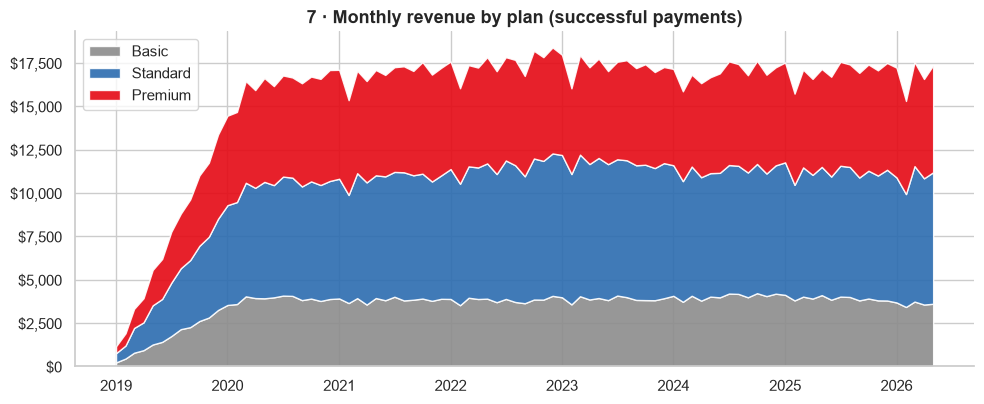

Takeaway: monthly revenue peaked at $18,396 in Dec 2022; latest full month (May 2026) is $17,365.


In [10]:
# 7 monthly revenue trend by plan
mr = pr.assign(m=pr.payment_date.dt.to_period('M').dt.to_timestamp()).pivot_table(index='m', columns='plan_name', values='amount', aggfunc='sum')[order]
fig, ax = plt.subplots(figsize=(10,4.2)); ax.stackplot(mr.index, mr.T.values, labels=order, colors=[GREY, BLUE, RED], alpha=.9); ax.legend(loc='upper left')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}')); ax.set_title('7 · Monthly revenue by plan (successful payments)'); save(fig, 'revenue_monthly')
tot = mr.sum(axis=1); take(f"monthly revenue peaked at ${tot.max():,.0f} in {tot.idxmax():%b %Y}; latest full month ({tot.index[-1]:%b %Y}) is ${tot.iloc[-1]:,.0f}.")

## C · Cancellations

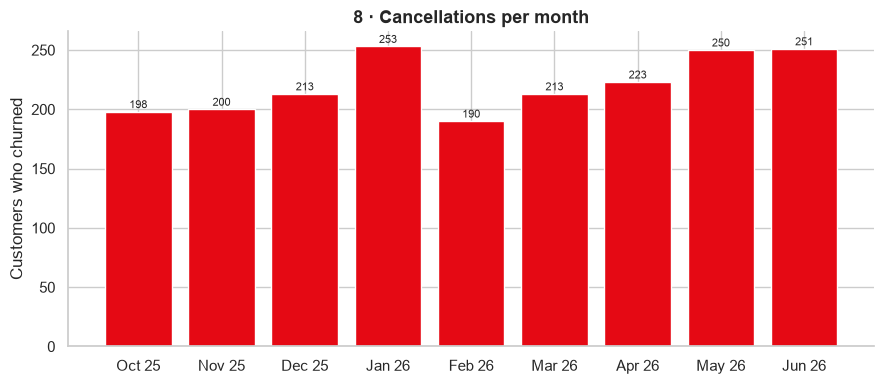

Takeaway: cancellations are recorded from Oct 2025 onwards (9 months); the peak is Jan 2026 with 253 cancellations. No churn dates exist before Oct 2025.


In [11]:
# 8 cancellations over time
cm = churn[churn.churned].set_index('churn_date').resample('MS').size()
fig, ax = plt.subplots(figsize=(9,4)); ax.bar(cm.index.strftime('%b %y'), cm.values, color=RED)
for i, v in enumerate(cm.values): ax.text(i, v+3, v, ha='center', fontsize=8)
ax.set_title('8 · Cancellations per month'); ax.set_ylabel('Customers who churned'); save(fig, 'cancellations_monthly')
take(f"cancellations are recorded from {cm.index[0]:%b %Y} onwards ({len(cm)} months); the peak is {cm.idxmax():%b %Y} with {cm.max()} cancellations. No churn dates exist before Oct 2025.")

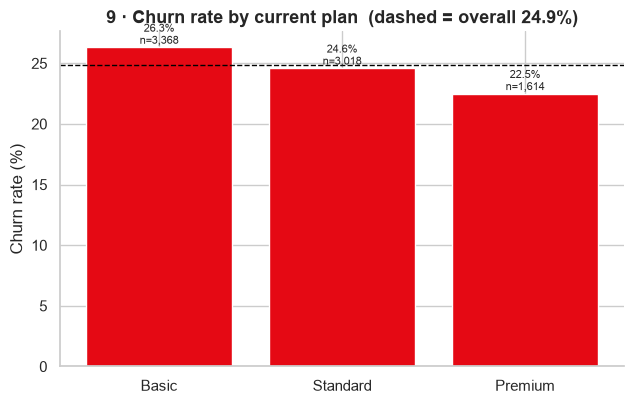

Takeaway: churn by plan: Basic 26.3%, Standard 24.6%, Premium 22.5%.


In [12]:
# 9 churn by plan
g = churn_bar('plan_name', '9 · Churn rate by current plan', 'churn_by_plan', order=order, figsize=(6.5,4.2))
take(f"churn by plan: " + ', '.join(f"{r.plan_name} {r.churn_rate:.1%}" for r in g.itertuples()) + ".")

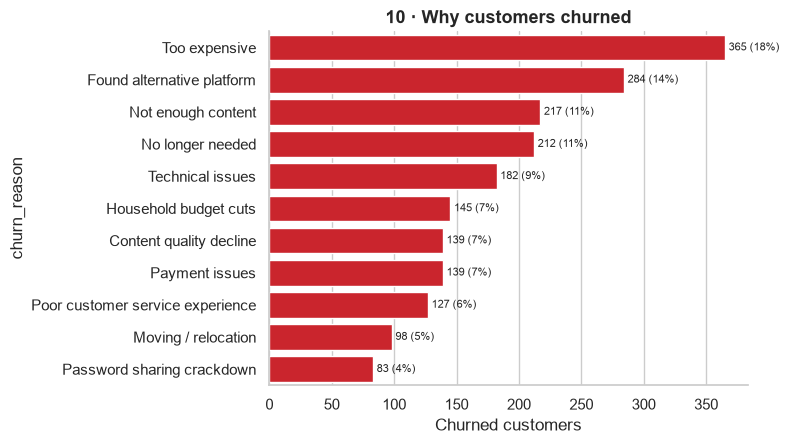

Takeaway: 'Too expensive' is the #1 reason (18%); price-related reasons (Too expensive + Household budget cuts) = 26%.


In [13]:
# 10 churn reasons
s = churn[churn.churned].churn_reason.value_counts()
fig, ax = plt.subplots(figsize=(8,4.6)); sns.barplot(x=s.values, y=s.index, color=RED, ax=ax)
for i, v in enumerate(s.values): ax.text(v+3, i, f'{v} ({v/s.sum():.0%})', va='center', fontsize=8)
ax.set_title('10 · Why customers churned'); ax.set_xlabel('Churned customers'); save(fig, 'churn_reasons')
take(f"'{s.index[0]}' is the #1 reason ({s.iloc[0]/s.sum():.0%}); price-related reasons (Too expensive + Household budget cuts) = {(s['Too expensive']+s['Household budget cuts'])/s.sum():.0%}.")

## D · Engagement

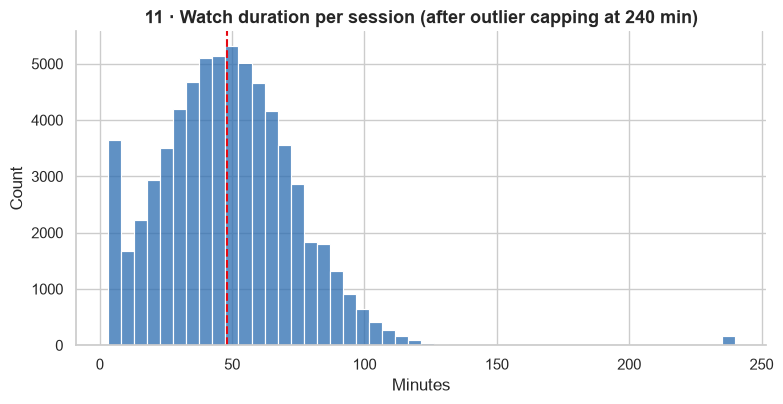

Takeaway: median session 48 min, mean 48 min; 0.24% of sessions sit at the 240-min cap.


In [14]:
# 11 watch duration per session
fig, ax = plt.subplots(figsize=(8,4.2)); sns.histplot(viewing.watch_duration_minutes, bins=48, color=BLUE, ax=ax)
ax.axvline(viewing.watch_duration_minutes.median(), color=RED, ls='--'); ax.set_title('11 · Watch duration per session (after outlier capping at 240 min)'); ax.set_xlabel('Minutes'); save(fig, 'watch_duration_distribution')
take(f"median session {viewing.watch_duration_minutes.median():.0f} min, mean {viewing.watch_duration_minutes.mean():.0f} min; {(viewing.watch_duration_minutes>=240).mean():.2%} of sessions sit at the 240-min cap.")

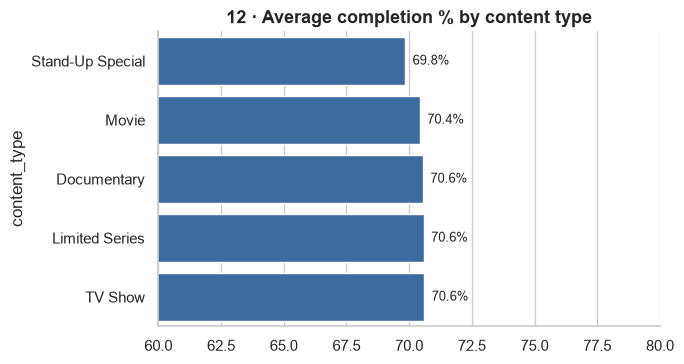

Takeaway: TV Show has the highest completion (70.6%), Stand-Up Special the lowest (69.8%); the spread is only 0.8 points.


In [15]:
# 12 completion by content type
vc = viewing.merge(content[['content_id','content_type','genre']], on='content_id')
s = vc.groupby('content_type').completion_percentage.mean().sort_values()
fig, ax = plt.subplots(figsize=(7,3.8)); sns.barplot(x=s.values, y=s.index, color=BLUE, ax=ax)
for i, v in enumerate(s.values): ax.text(v+.3, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlim(60, 80); ax.set_title('12 · Average completion % by content type'); save(fig, 'completion_by_type')
take(f"{s.index[-1]} has the highest completion ({s.iloc[-1]:.1f}%), {s.index[0]} the lowest ({s.iloc[0]:.1f}%); the spread is only {s.iloc[-1]-s.iloc[0]:.1f} points.")

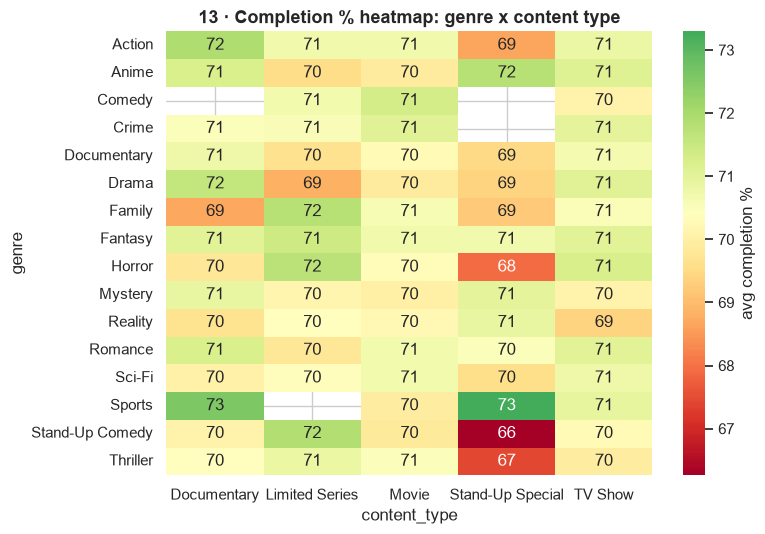

Takeaway: highest cell ('Sports', 'Stand-Up Special') = 73%, lowest ('Stand-Up Comedy', 'Stand-Up Special') = 66% (small cells are noisy).


In [16]:
# 13 heatmap completion type x genre
h = vc.pivot_table(index='genre', columns='content_type', values='completion_percentage', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8,5.5)); sns.heatmap(h, annot=True, fmt='.0f', cmap='RdYlGn', center=h.stack().mean(), cbar_kws={'label':'avg completion %'}, ax=ax)
ax.set_title('13 · Completion % heatmap: genre x content type'); save(fig, 'completion_heatmap')
st = h.stack(); take(f"highest cell {st.idxmax()} = {st.max():.0f}%, lowest {st.idxmin()} = {st.min():.0f}% (small cells are noisy).")

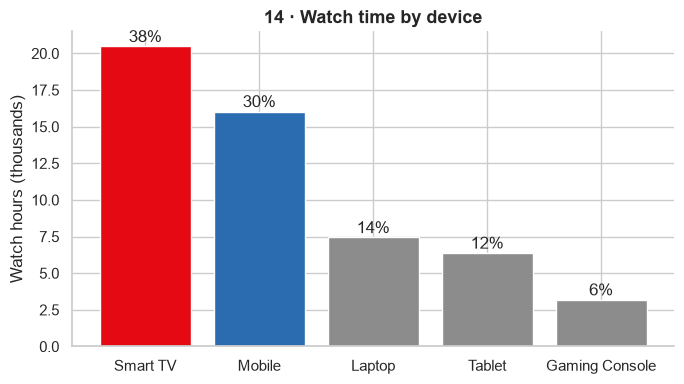

Takeaway: Smart TV drives 38% of watch time, then Mobile (30%).


In [17]:
# 14 device share
d = viewing.groupby('device_type').watch_duration_minutes.sum().sort_values(ascending=False); d = d[d.index != 'Unknown']
fig, ax = plt.subplots(figsize=(7,4)); bars = ax.bar(d.index, d.values/60/1000, color=[RED, BLUE, GREY, GREY, GREY][:len(d)])
for b, v in zip(bars, d.values): ax.text(b.get_x()+b.get_width()/2, b.get_height()+.3, f'{v/d.sum():.0%}', ha='center')
ax.set_ylabel('Watch hours (thousands)'); ax.set_title('14 · Watch time by device'); save(fig, 'device_share')
take(f"{d.index[0]} drives {d.iloc[0]/d.sum():.0%} of watch time, then {d.index[1]} ({d.iloc[1]/d.sum():.0%}).")

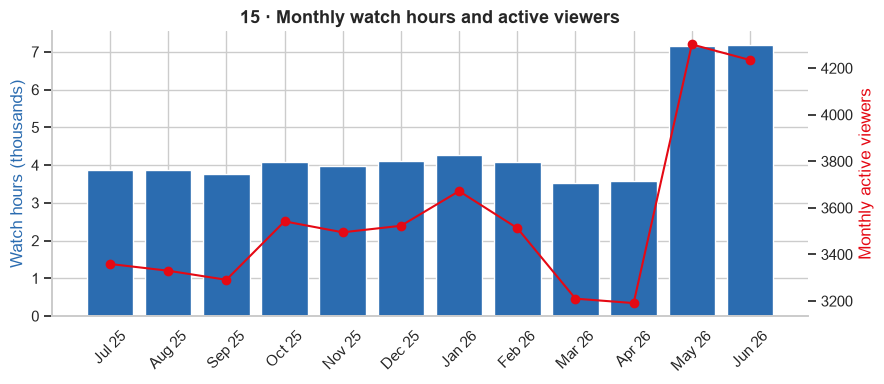

Takeaway: watch time ranges 3.5K-7.2K hours/month; active viewers 3,191-4,302. Viewing logs only cover Jul 2025 - Jun 2026.


In [18]:
# 15 monthly viewing minutes + active viewers
mv = viewing.assign(m=viewing.viewing_date.dt.to_period('M').dt.to_timestamp()).groupby('m').agg(hours=('watch_duration_minutes', lambda x: x.sum()/60), viewers=('customer_id','nunique'))
fig, ax = plt.subplots(figsize=(9,4)); ax.bar(mv.index.strftime('%b %y'), mv.hours/1000, color=BLUE); ax.set_ylabel('Watch hours (thousands)', color=BLUE)
ax2 = ax.twinx(); ax2.plot(mv.index.strftime('%b %y'), mv.viewers, color=RED, marker='o'); ax2.set_ylabel('Monthly active viewers', color=RED); ax2.grid(False)
ax.set_title('15 · Monthly watch hours and active viewers'); plt.setp(ax.get_xticklabels(), rotation=45); save(fig, 'viewing_monthly')
take(f"watch time ranges {mv.hours.min()/1000:.1f}K-{mv.hours.max()/1000:.1f}K hours/month; active viewers {mv.viewers.min():,}-{mv.viewers.max():,}. Viewing logs only cover Jul 2025 - Jun 2026.")

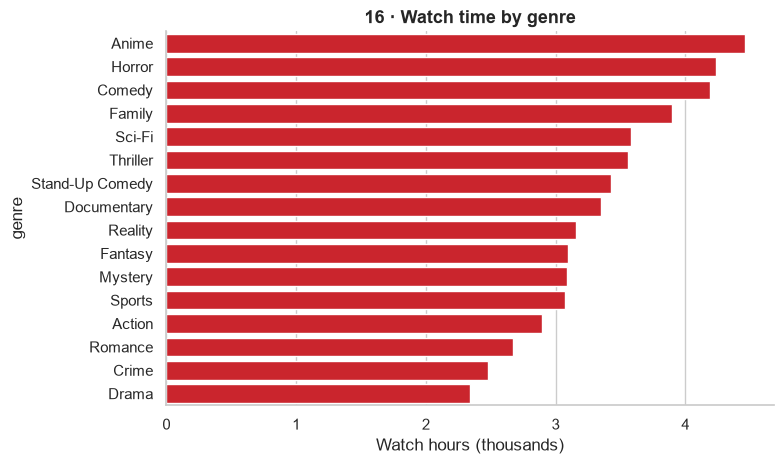

Takeaway: Anime leads (8% of hours), Horror second; bottom genre is Drama.


In [19]:
# 16 top genres by watch hours
g = vc.groupby('genre').watch_duration_minutes.sum().sort_values(ascending=False)/60
fig, ax = plt.subplots(figsize=(8,4.8)); sns.barplot(x=g.values/1000, y=g.index, color=RED, ax=ax); ax.set_xlabel('Watch hours (thousands)')
ax.set_title('16 · Watch time by genre'); save(fig, 'genre_watch_time')
take(f"{g.index[0]} leads ({g.iloc[0]/g.sum():.0%} of hours), {g.index[1]} second; bottom genre is {g.index[-1]}.")

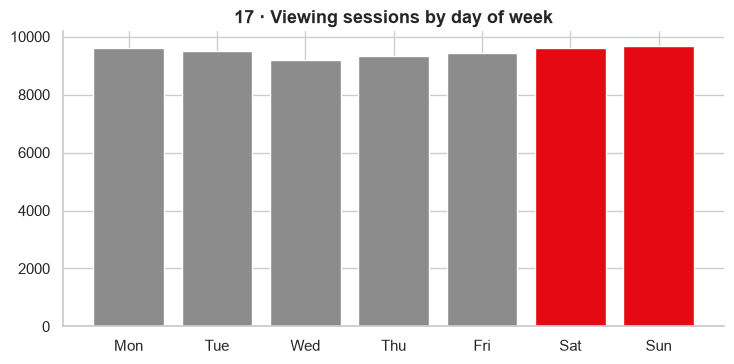

Takeaway: Sunday is the busiest day (9,692 sessions); weekends account for 29% of sessions (even split would be 29%).


In [20]:
# 17 weekday pattern
w = viewing.groupby(viewing.viewing_date.dt.day_name()).size().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
fig, ax = plt.subplots(figsize=(7.5,3.8)); bars = ax.bar(w.index.str[:3], w.values, color=[GREY]*5+[RED]*2)
ax.set_title('17 · Viewing sessions by day of week'); save(fig, 'weekday_pattern')
take(f"{w.idxmax()} is the busiest day ({w.max():,} sessions); weekends account for {(w['Saturday']+w['Sunday'])/w.sum():.0%} of sessions (even split would be 29%).")

## E · What predicts churn?
Churn rate for each customer group. The dashed line is the overall rate (24.9%); bars well above it flag fragile segments, and this is the groundwork for the feature-engineering and modelling steps.

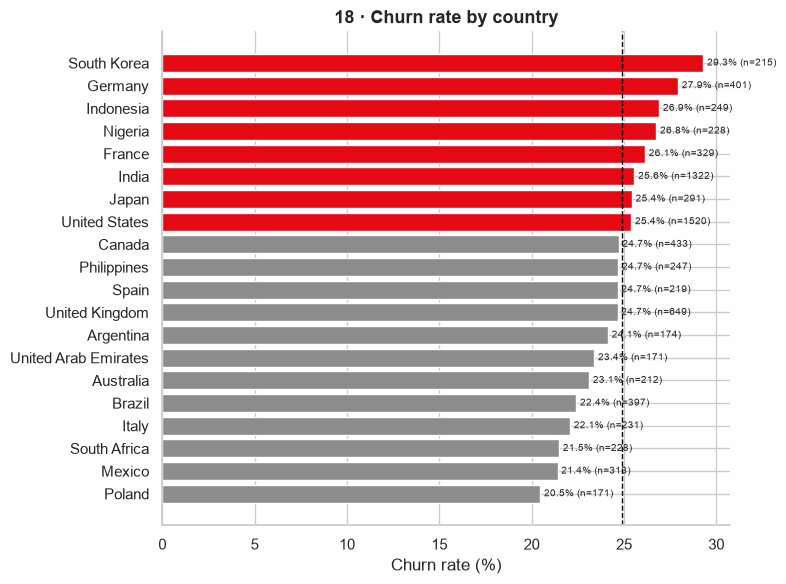

Takeaway: highest: South Korea (29.3%), lowest: Poland (20.5%); range is 8.8 pts but country samples are small (n=140-1,500).


In [21]:
# 18 churn by country
g = cust.groupby('country').agg(customers=('churned','size'), churn_rate=('churned','mean')).sort_values('churn_rate', ascending=False)
fig, ax = plt.subplots(figsize=(8,6)); colors = [RED if r > BASE else GREY for r in g.churn_rate]
ax.barh(g.index, g.churn_rate*100, color=colors); ax.invert_yaxis(); ax.axvline(BASE*100, color='black', ls='--', lw=1)
for i, (r, n) in enumerate(zip(g.churn_rate, g.customers)): ax.text(r*100+.2, i, f'{r:.1%} (n={n})', va='center', fontsize=7)
ax.set_xlabel('Churn rate (%)'); ax.set_title('18 · Churn rate by country'); save(fig, 'churn_by_country')
take(f"highest: {g.index[0]} ({g.churn_rate.iloc[0]:.1%}), lowest: {g.index[-1]} ({g.churn_rate.iloc[-1]:.1%}); range is {(g.churn_rate.max()-g.churn_rate.min())*100:.1f} pts but country samples are small (n=140-1,500).")

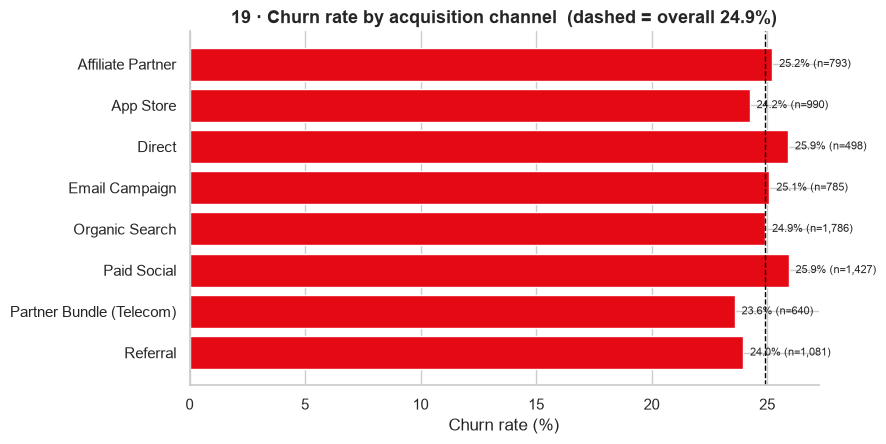

Takeaway: channel churn only spans 23.6% (Partner Bundle (Telecom)) to 25.9% (Paid Social): channel is a weak predictor.


In [22]:
g = churn_bar('acquisition_channel', '19 · Churn rate by acquisition channel', 'churn_by_channel', horizontal=True, figsize=(9,4.6)).sort_values('churn_rate')
take(f"channel churn only spans {g.churn_rate.min():.1%} ({g.iloc[0].acquisition_channel}) to {g.churn_rate.max():.1%} ({g.iloc[-1].acquisition_channel}): channel is a weak predictor.")

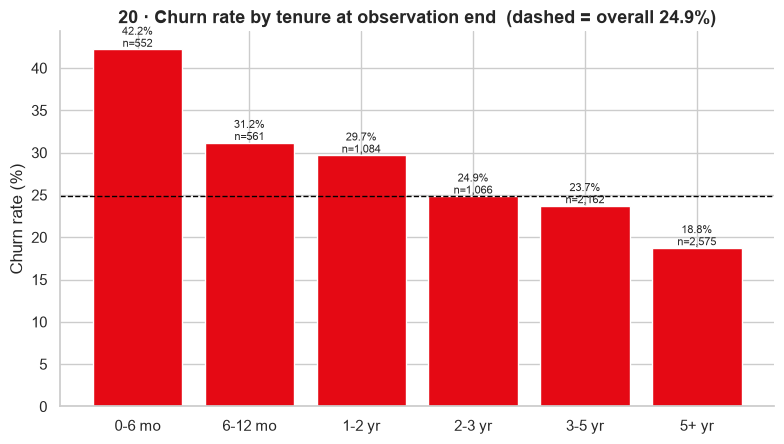

Takeaway: churn is 42.2% for customers under 6 months vs 18.8% for 5+ years: newer customers are more fragile.


In [23]:
g = churn_bar('tenure_bucket', '20 · Churn rate by tenure at observation end', 'churn_by_tenure', order=['0-6 mo','6-12 mo','1-2 yr','2-3 yr','3-5 yr','5+ yr'], figsize=(8,4.6))
take(f"churn is {g.churn_rate.iloc[0]:.1%} for customers under 6 months vs {g.churn_rate.iloc[-1]:.1%} for 5+ years: " + ('newer customers are more fragile.' if g.churn_rate.iloc[0] > g.churn_rate.iloc[-1] else 'no clear tenure protection.'))

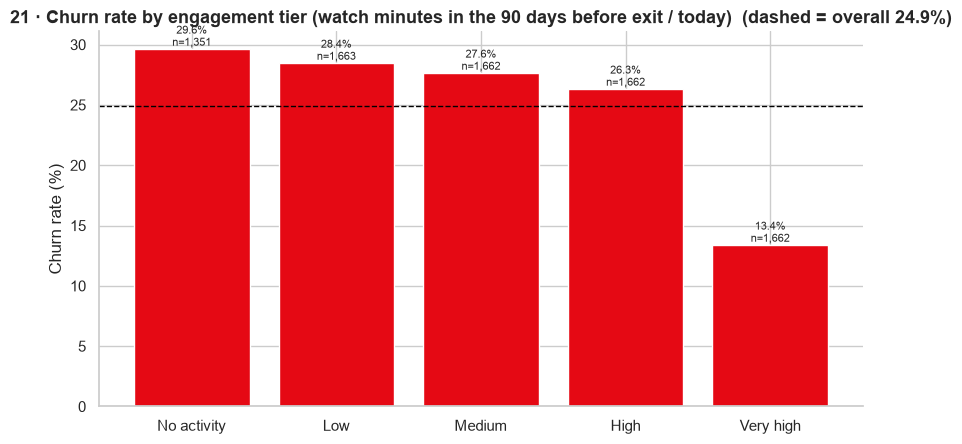

Takeaway: churn falls from 29.6% (no activity) / 28.4% (low) to 13.4% (very high): engagement is a primary churn signal.


In [24]:
g = churn_bar('engagement_tier', '21 · Churn rate by engagement tier (watch minutes in the 90 days before exit / today)', 'churn_by_engagement', order=['No activity','Low','Medium','High','Very high'], figsize=(8.5,4.6))
take(f"churn falls from {g.churn_rate.iloc[0]:.1%} (no activity) / {g.churn_rate.iloc[1]:.1%} (low) to {g.churn_rate.iloc[-1]:.1%} (very high): engagement is a primary churn signal.")

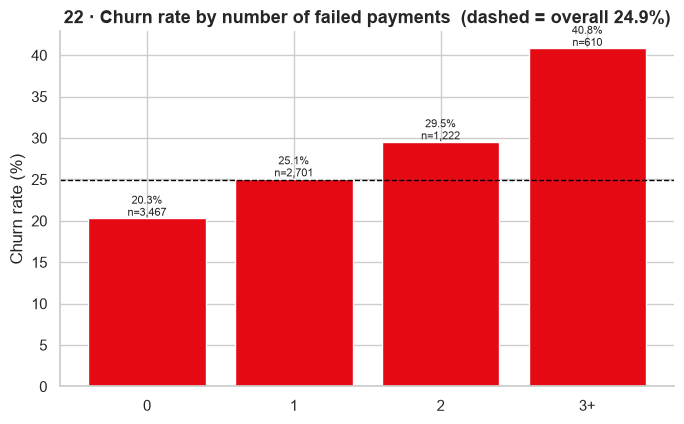

Takeaway: customers with 3+ failed payments churn at 40.8% vs 20.3% with none (2.0x).


In [25]:
g = churn_bar('failed_bucket', '22 · Churn rate by number of failed payments', 'churn_by_failed_payments', order=['0','1','2','3+'], figsize=(7,4.4))
take(f"customers with 3+ failed payments churn at {g.churn_rate.iloc[-1]:.1%} vs {g.churn_rate.iloc[0]:.1%} with none ({g.churn_rate.iloc[-1]/g.churn_rate.iloc[0]:.1f}x).")

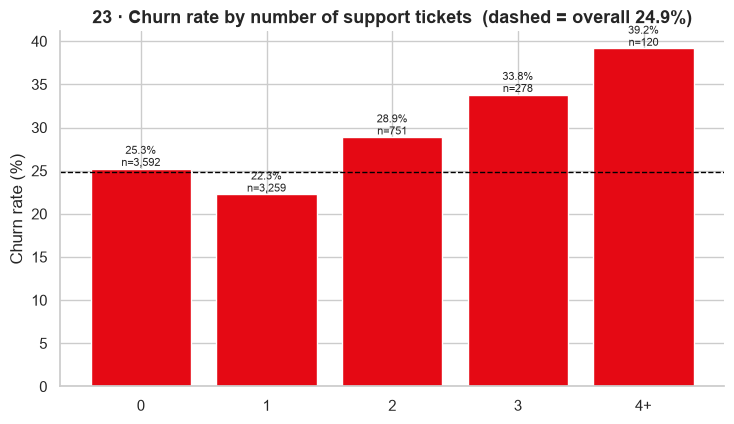

Takeaway: churn is 25.3% with no tickets and 39.2% with 4+ tickets.


In [26]:
g = churn_bar('ticket_bucket', '23 · Churn rate by number of support tickets', 'churn_by_tickets', order=['0','1','2','3','4+'], figsize=(7.5,4.4))
take(f"churn is {g.churn_rate.iloc[0]:.1%} with no tickets and {g.churn_rate.iloc[-1]:.1%} with 4+ tickets.")

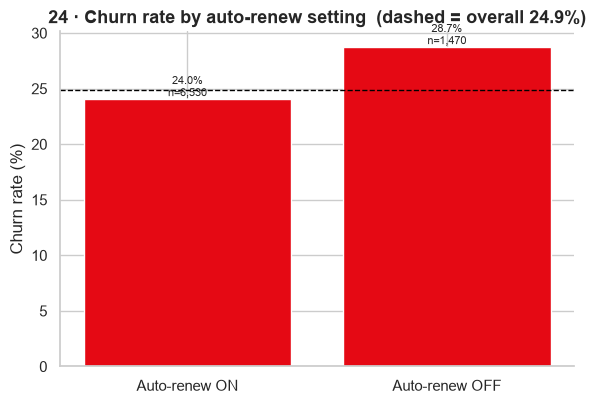

Takeaway: auto-renew OFF customers churn at 28.7% vs 24.0% for ON (1.2x).


In [27]:
cust['auto_renew_label'] = np.where(cust.auto_renew, 'Auto-renew ON', 'Auto-renew OFF')
g = churn_bar('auto_renew_label', '24 · Churn rate by auto-renew setting', 'churn_by_autorenew', order=['Auto-renew ON','Auto-renew OFF'], figsize=(6,4.2))
take(f"auto-renew OFF customers churn at {g.churn_rate.iloc[1]:.1%} vs {g.churn_rate.iloc[0]:.1%} for ON ({g.churn_rate.iloc[1]/g.churn_rate.iloc[0]:.1f}x).")

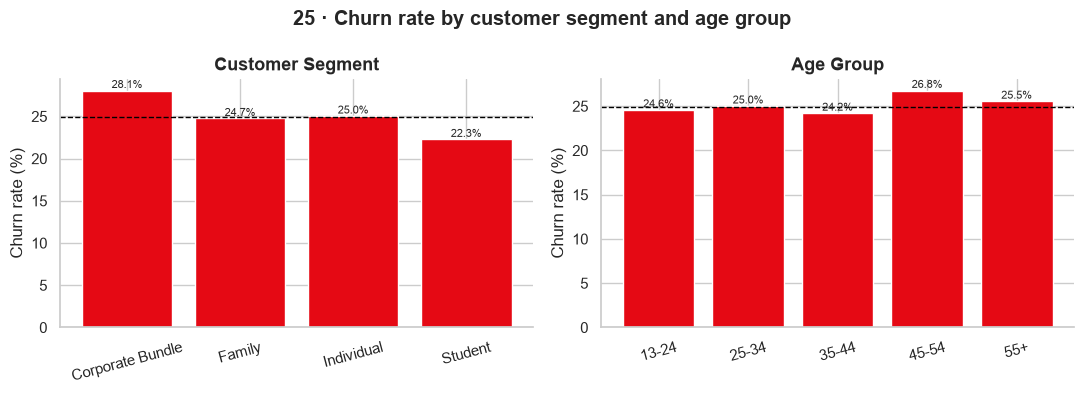

Takeaway: segment churn ranges 22.3% (Student) to 28.1% (Corporate Bundle).


In [28]:
# 25 churn by customer segment and age group (side by side)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, col, order_ in zip(axes, ['customer_segment','age_group'], [None, ['13-24','25-34','35-44','45-54','55+']]):
    g = cust.groupby(col, observed=True).churned.agg(['mean','size']);
    if order_: g = g.loc[order_]
    ax.bar(g.index.astype(str), g['mean']*100, color=RED); ax.axhline(BASE*100, color='black', ls='--', lw=1)
    for i, (r, n) in enumerate(zip(g['mean'], g['size'])): ax.text(i, r*100+.3, f'{r:.1%}', ha='center', fontsize=8)
    ax.set_title(col.replace('_',' ').title()); ax.set_ylabel('Churn rate (%)'); plt.setp(ax.get_xticklabels(), rotation=15)
fig.suptitle('25 · Churn rate by customer segment and age group', fontweight='bold'); save(fig, 'churn_by_segment_age')
seg = cust.groupby('customer_segment').churned.mean(); take(f"segment churn ranges {seg.min():.1%} ({seg.idxmin()}) to {seg.max():.1%} ({seg.idxmax()}).")

## F · Support & feedback

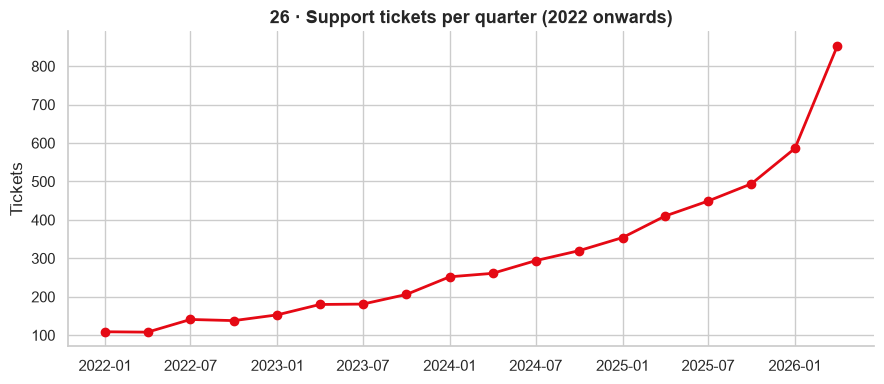

ValueError: Invalid format string

In [29]:
# 26 ticket volume trend
tm = tickets.dropna(subset=['ticket_date']).set_index('ticket_date').resample('QS').size(); tm = tm[tm.index >= '2022-01-01']
fig, ax = plt.subplots(figsize=(9,4)); ax.plot(tm.index, tm.values, marker='o', color=RED, lw=2)
ax.set_title('26 · Support tickets per quarter (2022 onwards)'); ax.set_ylabel('Tickets'); save(fig, 'ticket_volume_trend')
take(f"ticket volume rose from {tm.iloc[0]:,} in {tm.index[0]:%Y-Q%q}".replace('%q', str(tm.index[0].quarter)) + f" to {tm.iloc[-1]:,} in the latest quarter ({tm.index[-1]:%b %Y} start), a {tm.iloc[-1]/tm.iloc[0]:.1f}x increase.")

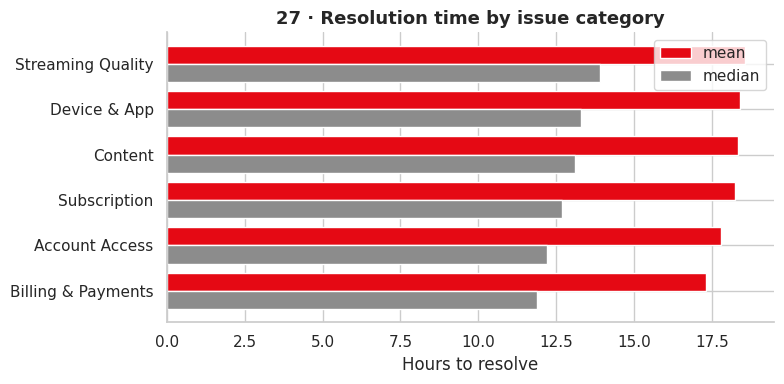

Takeaway: Streaming Quality takes longest (mean 18.6h), Billing & Payments the shortest (17.3h); means exceed medians, so a few very slow tickets skew the average.


In [ ]:
# 27 resolution time by category
r = tickets.dropna(subset=['resolution_time_hours']).groupby('issue_category').resolution_time_hours.agg(['mean','median']).sort_values('mean')
fig, ax = plt.subplots(figsize=(8,4)); y = np.arange(len(r)); ax.barh(y+.2, r['mean'], .4, color=RED, label='mean'); ax.barh(y-.2, r['median'], .4, color=GREY, label='median')
ax.set_yticks(y); ax.set_yticklabels(r.index); ax.legend(); ax.set_xlabel('Hours to resolve'); ax.set_title('27 · Resolution time by issue category'); save(fig, 'resolution_time')
take(f"{r.index[-1]} takes longest (mean {r['mean'].iloc[-1]:.1f}h), {r.index[0]} the shortest ({r['mean'].iloc[0]:.1f}h); means exceed medians, so a few very slow tickets skew the average.")

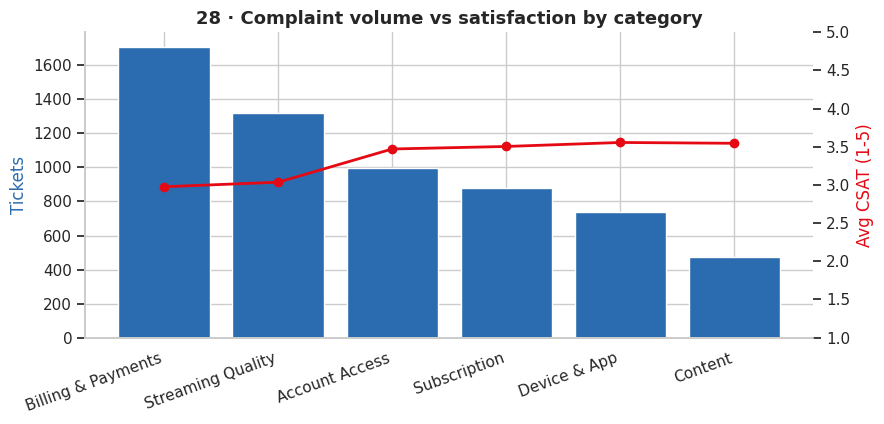

Takeaway: Billing & Payments is the biggest complaint area (1,709 tickets, 28%); lowest CSAT is Billing & Payments (2.98).


In [ ]:
# 28 complaint category frequency vs CSAT
cc = tickets.groupby('issue_category').agg(tickets=('ticket_id','count'), csat=('customer_satisfaction_score','mean')).sort_values('tickets', ascending=False)
fig, ax = plt.subplots(figsize=(9,4.4)); ax.bar(cc.index, cc.tickets, color=BLUE); ax.set_ylabel('Tickets', color=BLUE); plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
ax2 = ax.twinx(); ax2.plot(cc.index, cc.csat, color=RED, marker='o', lw=2); ax2.set_ylim(1, 5); ax2.set_ylabel('Avg CSAT (1-5)', color=RED); ax2.grid(False)
ax.set_title('28 · Complaint volume vs satisfaction by category'); save(fig, 'complaints_vs_csat')
take(f"{cc.index[0]} is the biggest complaint area ({cc.tickets.iloc[0]:,} tickets, {cc.tickets.iloc[0]/cc.tickets.sum():.0%}); lowest CSAT is {cc.csat.idxmin()} ({cc.csat.min():.2f}).")

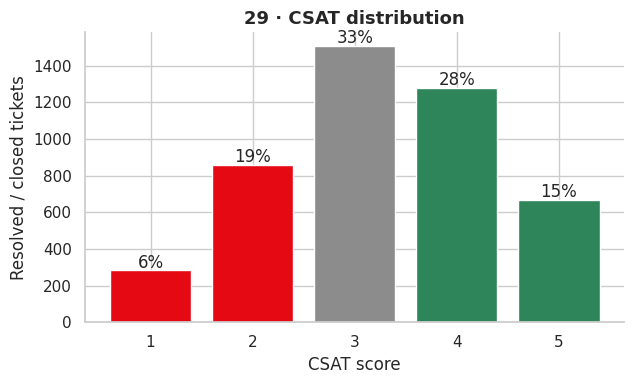

Takeaway: 25% of scored tickets are dissatisfied (1-2) vs 42% satisfied (4-5); mean 3.26.


In [ ]:
# 29 CSAT distribution
cs = tickets.customer_satisfaction_score.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5,4)); bars = ax.bar(cs.index.astype(int).astype(str), cs.values, color=[RED, RED, GREY, GREEN, GREEN])
for b, v in zip(bars, cs.values): ax.text(b.get_x()+b.get_width()/2, v+15, f'{v/cs.sum():.0%}', ha='center')
ax.set_xlabel('CSAT score'); ax.set_ylabel('Resolved / closed tickets'); ax.set_title('29 · CSAT distribution'); save(fig, 'csat_distribution')
take(f"{(cs.loc[1]+cs.loc[2])/cs.sum():.0%} of scored tickets are dissatisfied (1-2) vs {(cs.loc[4]+cs.loc[5])/cs.sum():.0%} satisfied (4-5); mean {tickets.customer_satisfaction_score.mean():.2f}.")

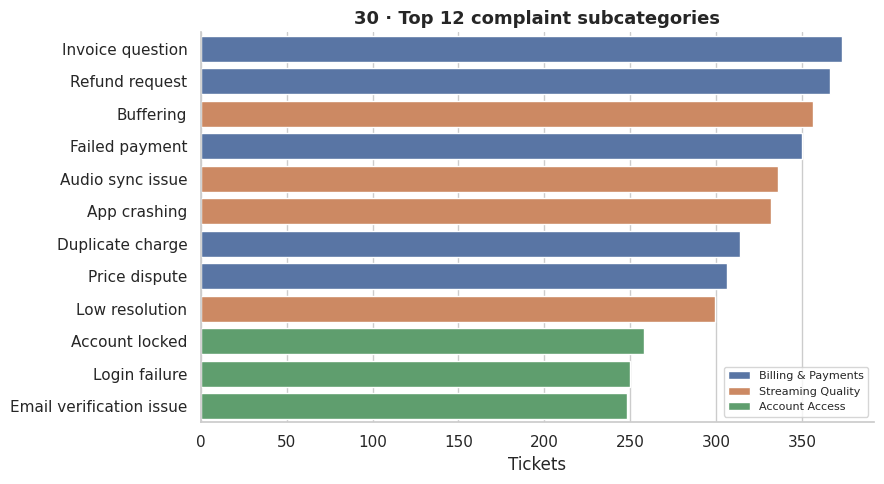

Takeaway: 'Invoice question' (Billing & Payments) is the most frequent specific complaint with 373 tickets.


In [ ]:
# 30 top ticket subcategories
s = tickets.groupby(['issue_category','issue_subcategory']).size().sort_values(ascending=False).head(12).reset_index(name='n')
fig, ax = plt.subplots(figsize=(9,5)); sns.barplot(data=s, x='n', y='issue_subcategory', hue='issue_category', dodge=False, ax=ax); ax.legend(title='', fontsize=8, loc='lower right')
ax.set_title('30 · Top 12 complaint subcategories'); ax.set_xlabel('Tickets'); ax.set_ylabel(''); save(fig, 'top_subcategories')
take(f"'{s.issue_subcategory.iloc[0]}' ({s.issue_category.iloc[0]}) is the most frequent specific complaint with {s.n.iloc[0]} tickets.")

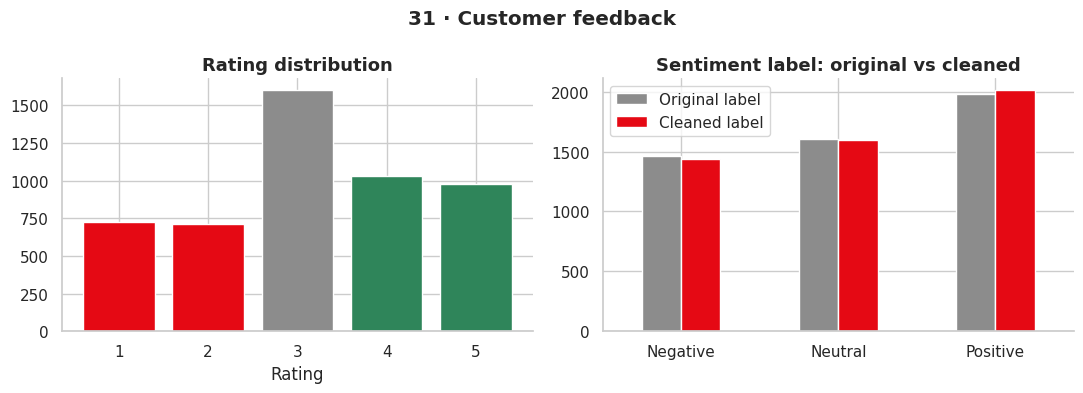

Takeaway: 28% of feedback is negative, 40% positive; 5.2% of original labels were wrong and re-derived from rating.


In [ ]:
# 31 feedback: rating distribution and label cleaning effect
fig, axes = plt.subplots(1, 2, figsize=(11,4))
rt = feedback.rating.value_counts().sort_index(); axes[0].bar(rt.index.astype(str), rt.values, color=[RED, RED, GREY, GREEN, GREEN]); axes[0].set_title('Rating distribution'); axes[0].set_xlabel('Rating')
lab = pd.DataFrame({'Original label': feedback.sentiment_label_original.value_counts(), 'Cleaned label': feedback.sentiment_label.value_counts()}).loc[['Negative','Neutral','Positive']]
lab.plot.bar(ax=axes[1], color=[GREY, RED], rot=0); axes[1].set_title('Sentiment label: original vs cleaned'); axes[1].set_xlabel('')
fig.suptitle('31 · Customer feedback', fontweight='bold'); save(fig, 'feedback_ratings_sentiment')
chg = (feedback.sentiment_label != feedback.sentiment_label_original).mean()
take(f"{(feedback.sentiment_label=='Negative').mean():.0%} of feedback is negative, {(feedback.sentiment_label=='Positive').mean():.0%} positive; {chg:.1%} of original labels were wrong and re-derived from rating.")

## G · Correlation overview

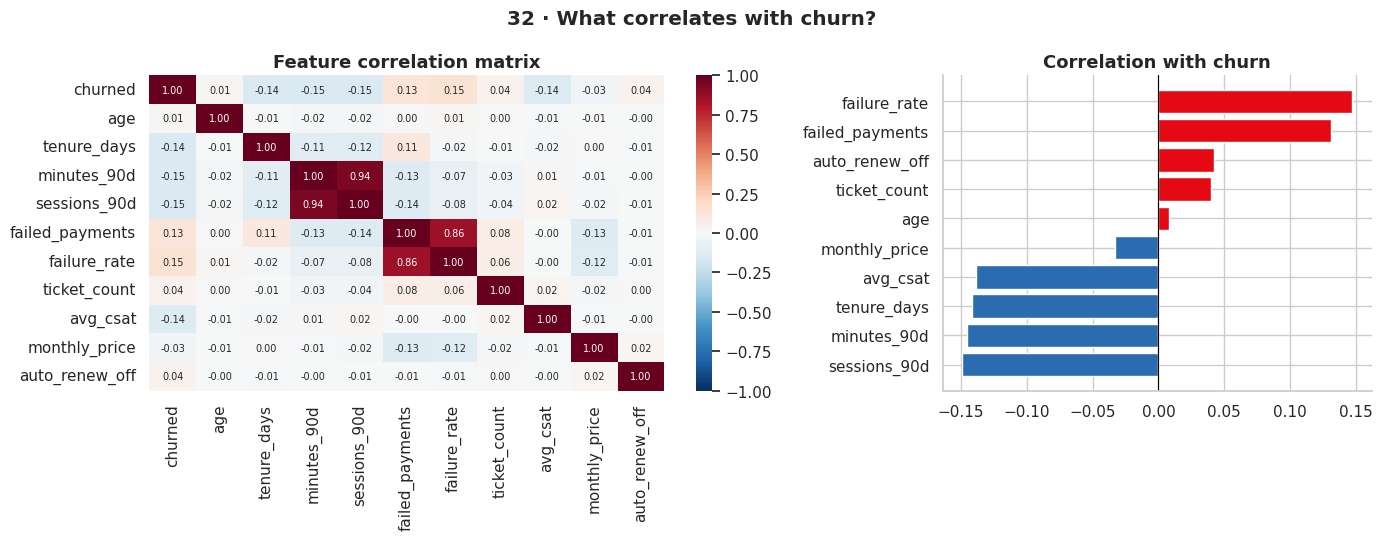

Takeaway: strongest positive link to churn: failure_rate (r=0.15); strongest negative: sessions_90d (r=-0.15).


In [ ]:
# 32 correlation of customer-level features with churn
cols = ['churned','age','tenure_days','minutes_90d','sessions_90d','failed_payments','failure_rate','ticket_count','avg_csat','monthly_price']
cm_ = cust[cols].assign(auto_renew_off=(~cust.auto_renew.astype(bool)).astype(int)).corr()
fig, axes = plt.subplots(1, 2, figsize=(14,5.5), gridspec_kw={'width_ratios':[1.5,1]})
sns.heatmap(cm_, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0], annot_kws={'size':7}); axes[0].set_title('Feature correlation matrix')
c = cm_['churned'].drop('churned').sort_values(); axes[1].barh(c.index, c.values, color=[RED if v>0 else BLUE for v in c.values]); axes[1].axvline(0, color='black', lw=.8); axes[1].set_title('Correlation with churn')
fig.suptitle('32 · What correlates with churn?', fontweight='bold'); save(fig, 'correlation_with_churn')
take(f"strongest positive link to churn: {c.idxmax()} (r={c.max():.2f}); strongest negative: {c.idxmin()} (r={c.min():.2f}).")

## Summary table: churn rate by every dimension tested

In [ ]:
rows = []
for col in ['plan_name','acquisition_channel','customer_segment','age_group','tenure_bucket','engagement_tier','failed_bucket','ticket_bucket','auto_renew_label','country']:
    g = cust.groupby(col, observed=True).churned.mean()
    rows.append({'dimension': col, 'lowest_group': str(g.idxmin()), 'lowest_churn': f'{g.min():.1%}', 'highest_group': str(g.idxmax()), 'highest_churn': f'{g.max():.1%}', 'spread_pts': round((g.max()-g.min())*100, 1)})
spread = pd.DataFrame(rows).sort_values('spread_pts', ascending=False).reset_index(drop=True)
print(f'{_n[0]} charts saved to reports/figures/'); spread

32 charts saved to reports/figures/


,dimension,lowest_group,lowest_churn,highest_group,highest_churn,spread_pts
0,tenure_bucket,5+ yr,18.8%,0-6 mo,42.2%,23.5
1,failed_bucket,0,20.3%,3+,40.8%,20.5
2,ticket_bucket,1,22.3%,4+,39.2%,16.9
3,engagement_tier,Very high,13.4%,No activity,29.6%,16.3
4,country,Poland,20.5%,South Korea,29.3%,8.8
5,customer_segment,Student,22.3%,Corporate Bundle,28.1%,5.8
6,auto_renew_label,Auto-renew ON,24.0%,Auto-renew OFF,28.7%,4.7
7,plan_name,Premium,22.5%,Basic,26.3%,3.8
8,age_group,35-44,24.2%,45-54,26.8%,2.6
9,acquisition_channel,Partner Bundle (Telecom),23.6%,Paid Social,25.9%,2.3
